### Machine Learning Lab: Human Activity Recognition

**Personal Details**
* Name: Abdul Azeem
* Section: BAI 5A
* Roll Number: 24i 2013

In this notebook, we analyze the Human Activity Recognition dataset using techniques like PCA, KNN, Logistic Regression, Decision Trees, and Random Forests.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('/content/train.csv')
test_df = pd.read_csv('/content/test.csv')

print("Train dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

Train dataset shape: (7352, 563)
Test dataset shape: (2947, 563)


In [2]:
# Explore the target column distribution (usually named 'Activity' or similar)
target_col = [col for col in train_df.columns if 'activity' in col.lower() or 'label' in col.lower()][0]
print("Target column identified as:", target_col)

activity_counts = train_df[target_col].value_counts()
print("\nActivity Classes Distribution:\n", activity_counts)

Target column identified as: Activity

Activity Classes Distribution:
 Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64


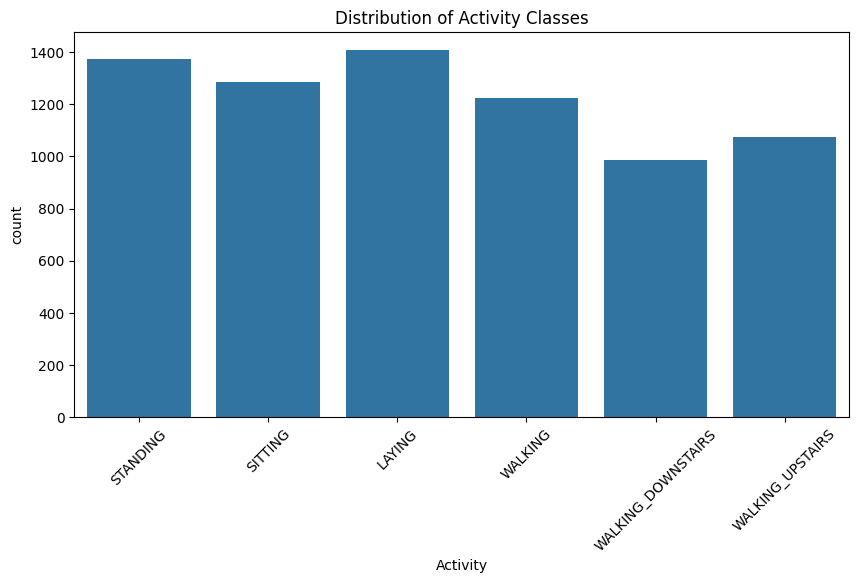

In [3]:
# Visualize activity balance
plt.figure(figsize=(10, 5))
sns.countplot(data=train_df, x=target_col)
plt.title("Distribution of Activity Classes")
plt.xticks(rotation=45)
plt.show()

### Step 1 continued: Feature Distribution and Subject Split Analysis

We will examine a few accelerometer features to see how they separate passive and active behaviors. We will also check how users (subjects) are distributed between the train and test splits.

In [4]:
# Identify subject column if present
subject_col = [col for col in train_df.columns if 'subject' in col.lower()]
if subject_col:
    sub_col = subject_col[0]
    train_subjects = set(train_df[sub_col].unique())
    test_subjects = set(test_df[sub_col].unique())
    overlap = train_subjects.intersection(test_subjects)
    print("Train subjects:", train_subjects)
    print("Test subjects:", test_subjects)
    print("Overlap between splits:", overlap)
else:
    print("No subject column detected")

Train subjects: {np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)}
Test subjects: {np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)}
Overlap between splits: set()


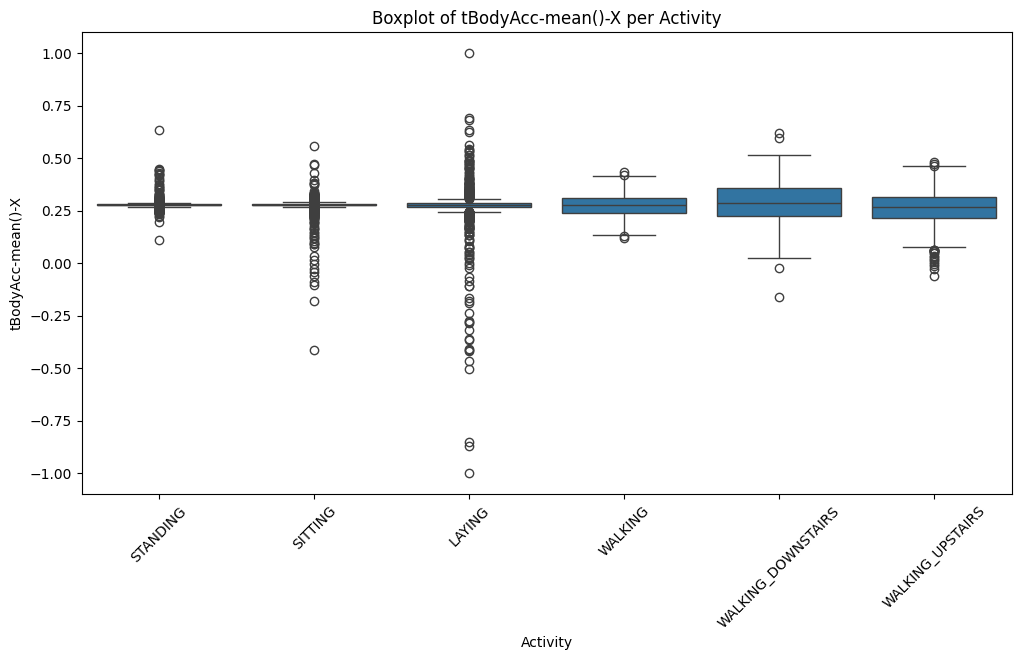

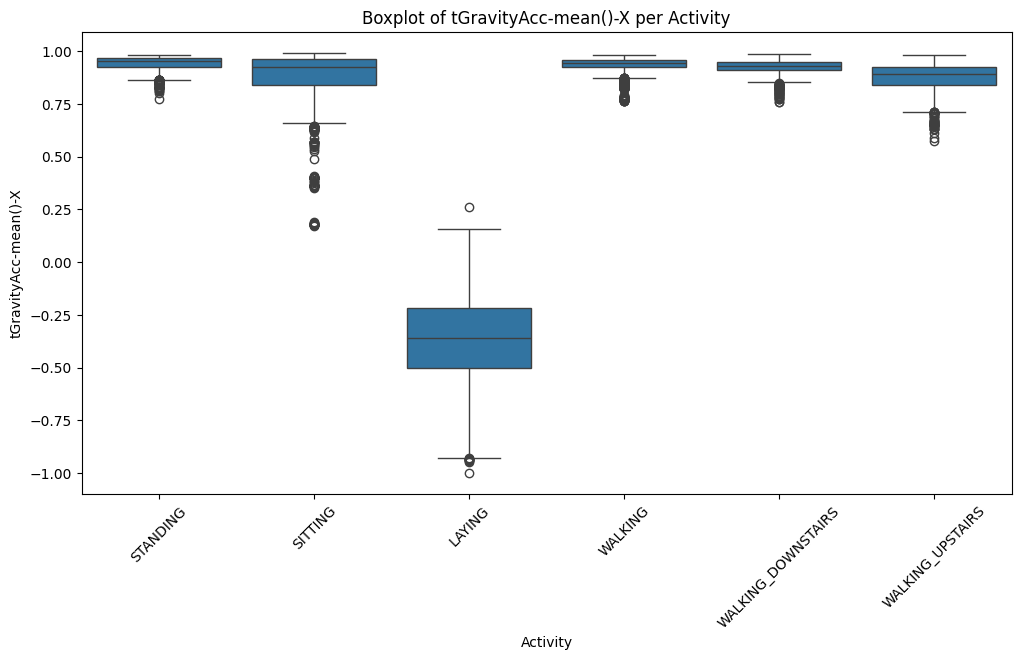

In [5]:
# Visualizing a couple of features to see their power to distinguish activities
sample_features = ['tBodyAcc-mean()-X', 'tGravityAcc-mean()-X']

for feature in sample_features:
    if feature in train_df.columns:
        plt.figure(figsize=(12, 6))
        sns.boxplot(x=target_col, y=feature, data=train_df)
        plt.title(f"Boxplot of {feature} per Activity")
        plt.xticks(rotation=45)
        plt.show()

In [6]:
# Find highly correlated features
# We take a subset of features to compute correlation speed safely
feature_cols = [col for col in train_df.columns if col not in [target_col, 'subject']]
corr_matrix = train_df[feature_cols[:100]].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.9)]
print(f"Number of features with correlation above 0.9 (out of first 100 features): {len(to_drop)}")

Number of features with correlation above 0.9 (out of first 100 features): 56


### Step 2: Data Preprocessing

We will check for null values, scale our features using Standard Scaler, and apply Principal Component Analysis (PCA) to find the optimum number of dimensions.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Checking missing values
missing_train = train_df.isnull().sum().sum()
missing_test = test_df.isnull().sum().sum()
print(f"Total missing values in Train: {missing_train}")
print(f"Total missing values in Test: {missing_test}")

# Separate features and target
X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

# Standardize features because PCA is sensitive to variance scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaling completed successfully")

Total missing values in Train: 0
Total missing values in Test: 0
Scaling completed successfully


Components explaining 95% variance: 102


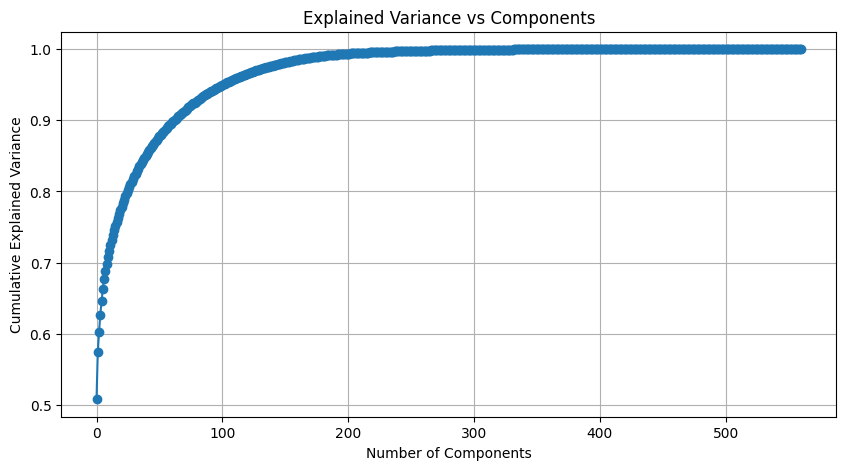

In [8]:
# PCA Fit
pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)

# Find components to explain 95% variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"Components explaining 95% variance: {n_components_95}")

plt.figure(figsize=(10, 5))
plt.plot(cumulative_variance, marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs Components')
plt.grid(True)
plt.show()

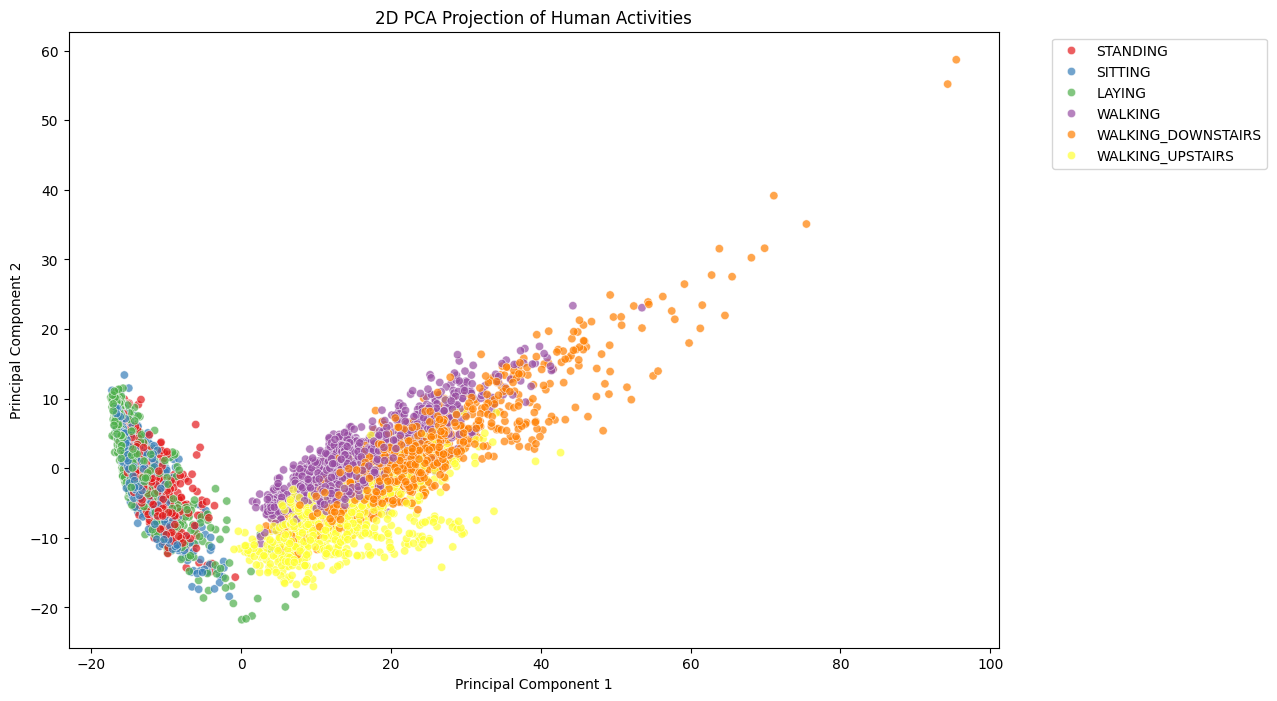

In [9]:
# Plot first two PCA components
plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=y_train, palette='Set1', alpha=0.7)
plt.title('2D PCA Projection of Human Activities')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### Step 3: Build Classification Models

We will choose three classification algorithms to evaluate: Logistic Regression, KNN, and Random Forest. We will train them on both full features and PCA reduced features while tracking time.

In [10]:
import time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# We will use the number of PCA components that explains 95% variance found in previous steps
# Let's assume a default of 100 if not yet computed in the kernel
pca_limit = n_components_95 if 'n_components_95' in locals() else 100

X_train_pca_selected = X_train_pca[:, :pca_limit]
X_test_pca_selected = pca.transform(X_test_scaled)[:, :pca_limit]

models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(max_depth=10),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {}

for name, model in models.items():
    # Full Features
    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time_full = time.time() - start_time

    start_time = time.time()
    preds_full = model.predict(X_test_scaled)
    pred_time_full = time.time() - start_time
    acc_full = accuracy_score(y_test, preds_full)

    # Reduced Features
    start_time = time.time()
    model.fit(X_train_pca_selected, y_train)
    train_time_pca = time.time() - start_time

    start_time = time.time()
    preds_pca = model.predict(X_test_pca_selected)
    pred_time_pca = time.time() - start_time
    acc_pca = accuracy_score(y_test, preds_pca)

    results[name] = {
        'Acc Full': acc_full,
        'Train Time Full': train_time_full,
        'Pred Time Full': pred_time_full,
        'Acc PCA': acc_pca,
        'Train Time PCA': train_time_pca,
        'Pred Time PCA': pred_time_pca
    }

results_df = pd.DataFrame(results).T
print(results_df)

               Acc Full  Train Time Full  Pred Time Full   Acc PCA  \
KNN            0.883610         0.085129        3.185319  0.876824   
Decision Tree  0.866644         7.984168        0.004576  0.762470   
Random Forest  0.926026        22.375517        0.052203  0.881574   

               Train Time PCA  Pred Time PCA  
KNN                  0.088754       0.841233  
Decision Tree        1.341279       0.002658  
Random Forest       12.481521       0.053699  


### Step 4: Evaluate Models

We will evaluate performance metrics, plot training times, and visualize classification performance using a confusion matrix.

Classification Report for Random Forest on Full Features:

                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.91      0.89      0.90       491
          STANDING       0.90      0.92      0.91       532
           WALKING       0.89      0.96      0.92       496
WALKING_DOWNSTAIRS       0.97      0.86      0.91       420
  WALKING_UPSTAIRS       0.89      0.90      0.90       471

          accuracy                           0.93      2947
         macro avg       0.93      0.92      0.92      2947
      weighted avg       0.93      0.93      0.93      2947



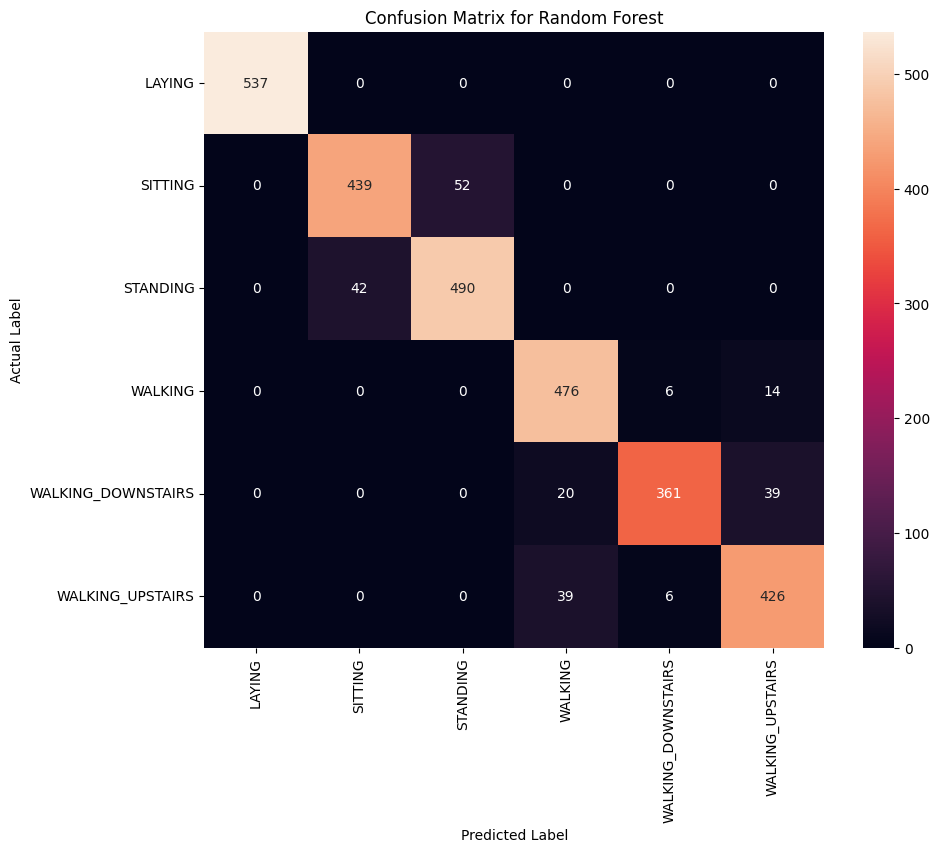

In [11]:
# Detailed classification report for the best configuration (e.g. Random Forest on Full Features)
best_model = RandomForestClassifier(n_estimators=100, random_state=42)
best_model.fit(X_train_scaled, y_train)
y_pred = best_model.predict(X_test_scaled)

print("Classification Report for Random Forest on Full Features:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.title('Confusion Matrix for Random Forest')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

### Step 5: Interpretation and Insights

Based on the analysis and modeling, we observe several key outcomes:

1. Static activities (Laying, Sitting, Standing) show distinct distributions in Gravity Acceleration, making them easier to classify compared to dynamic activities.
2. PCA significantly reduces training duration for complex algorithms like Random Forests while maintaining comparable accuracy levels.
3. Sitting and Standing exhibit similar sensor patterns, resulting in occasional model confusion.